# ДЗ3, проект "Cassava Leaf Disease Classification"
## Логинов Никита

### 1. Что проверяем

Берем лучшую модель из ДЗ2 - full_h1_h2, macro F1 = 0.4727.
Проверяем, где она ошибается, как качество зависит от условий съемки и что меняется при искажении фотографии.

Новые модели не обучаем. Используем те же 800 val изображений и те же метки.
Тест и leaderboard не используются.

In [7]:
import os
import json
import hashlib
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision
import sklearn
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.models import resnet18
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, confusion_matrix
from sklearn.preprocessing import label_binarize
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/analysis.json").is_file())
CFG = json.loads((ROOT / "configs/analysis.json").read_text())
CLASSES = ["CBB", "CBSD", "CGM", "CMD", "Healthy"]
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
PREDICTIONS = REPORTS / "predictions"
for p in [REPORTS, FIGURES, PREDICTIONS]:
    p.mkdir(parents=True, exist_ok=True)

def project_path(value):
    p = Path(value).expanduser()
    return p if p.is_absolute() else (ROOT / p).resolve()

SEED = CFG["seed"]
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(CFG["num_threads"])
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = torch.device(CFG["device"])
IMAGE_DIR = project_path(CFG["image_dir"])
checkpoint_path = project_path(CFG["checkpoint"])
manifest_path = project_path(CFG["manifest"])
assert hashlib.sha256(manifest_path.read_bytes()).hexdigest() == CFG["manifest_sha256"]
manifest = pd.read_csv(manifest_path)
reference = pd.read_csv(REPORTS / "reference/hw2_val_predictions.csv")
experiments = pd.read_csv(REPORTS / "reference/hw2_experiments.csv")
selected = experiments.sort_values("f1_macro", ascending=False).iloc[0]
assert selected["name"] == CFG["model_name"]
assert manifest.image_id.is_unique and reference.image_id.is_unique
train = manifest[manifest.split == "train"].reset_index(drop=True)
val_by_id = manifest[manifest.split == "val"].set_index("image_id")
assert set(reference.image_id) == set(val_by_id.index)
val = val_by_id.loc[reference.image_id].reset_index()[["image_id", "label"]]
assert val.label.tolist() == reference.label.tolist()
assert set(train.image_id).isdisjoint(val.image_id)
assert len(train) == 3200 and len(val) == 800
assert all((IMAGE_DIR / name).is_file() for name in manifest.image_id)

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
model.load_state_dict(checkpoint["state_dict"])
model = model.to(DEVICE).eval()
assert checkpoint["epoch"] == int(selected.best_epoch)

environment = dict(python=platform.python_version(), torch=str(torch.__version__),
    torchvision=str(torchvision.__version__), numpy=np.__version__, pandas=pd.__version__,
    sklearn=sklearn.__version__, device=str(DEVICE), model=CFG["model_name"],
    checkpoint_sha256=hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
    manifest_sha256=CFG["manifest_sha256"], seed=SEED)
(REPORTS / "environment.json").write_text(json.dumps(environment, ensure_ascii=False, indent=2))
display(experiments[["name", "class_weights", "augment", "best_epoch", "f1_macro"]].round(4))
print(f"Выбрана {selected['name']}; train={len(train)}, val={len(val)}; устройство: {DEVICE}")

,name,class_weights,augment,best_epoch,f1_macro
0,baseline,False,False,4,0.4405
1,only_h1,True,False,33,0.4712
2,only_h2,False,True,16,0.4720
3,full_h1_h2,True,True,4,0.4727


Выбрана full_h1_h2; train=3200, val=800; устройство: cpu


Конфигурация из ДЗ2: ResNet-18 ImageNet, взвешенный CrossEntropy и train-аугментации
RandomHorizontalFlip + ColorJitter. Resize 128, batch 128, 40 эпох, AdamW lr=1e-3,
weight_decay=0.01, seed=18. Заморожены первые 70% тензоров параметров; статистики BatchNorm обновлялись в train. Взяты веса лучшей эпохи - 4.

[Эксперимент ДЗ2](../../hw_2/reports/experiments_hw2.csv).
Разница с другими улучшенными вариантами маленькая; это выбор по текущему val, а не доказательство превосходства на новых данных.

In [8]:
class CassavaValidation(Dataset):
    def __init__(self, frame, brightness=1.0, noise_sigma=0.0):
        self.frame = frame.reset_index(drop=True)
        self.brightness = brightness
        self.noise_sigma = noise_sigma
        self.resize = T.Resize((CFG["size"], CFG["size"]))
        self.to_tensor = T.ToTensor()
        self.normalize = T.Normalize(CFG["mean"], CFG["std"])

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        with Image.open(IMAGE_DIR / row.image_id) as image:
            x = self.to_tensor(self.resize(image.convert("RGB")))
        x = (x * self.brightness).clamp(0, 1)
        if self.noise_sigma:
            # Одинаковый шум для одного фото при разных sigma, меняется только его сила.
            image_seed = int(hashlib.sha256(f"{SEED}/{row.image_id}".encode()).hexdigest()[:8], 16)
            generator = torch.Generator().manual_seed(image_seed)
            noise = torch.randn(x.shape, generator=generator)
            x = (x + self.noise_sigma * noise).clamp(0, 1)
        return self.normalize(x), int(row.label)

@torch.inference_mode()
def predict(frame, brightness=1.0, noise_sigma=0.0):
    dataset = CassavaValidation(frame, brightness=brightness, noise_sigma=noise_sigma)
    loader = DataLoader(dataset, batch_size=CFG["batch"], shuffle=False, num_workers=0)
    prob = []
    for x, _ in loader:
        prob.append(model(x.to(DEVICE)).softmax(1).cpu().numpy())
    return np.concatenate(prob)

def calculate_metrics(y, prob):
    pred = prob.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, labels=range(5), average="macro", zero_division=0)
    pc = precision_recall_fscore_support(y, pred, labels=range(5), zero_division=0)
    healthy = y == 4
    return dict(n=len(y), f1_macro=float(f1), precision_macro=float(p), recall_macro=float(r),
        accuracy=float((y == pred).mean()),
        average_precision_macro=float(average_precision_score(label_binarize(y, classes=range(5)), prob, average="macro")),
        f1_healthy=float(pc[2][4]), healthy_to_disease_rate=float((pred[healthy] != 4).mean()))

def save_predictions(name, prob):
    table = val.copy()
    table["prediction"] = prob.argmax(1)
    for k, label in enumerate(CLASSES):
        table[f"prob_{label}"] = prob[:, k]
    table.to_csv(PREDICTIONS / f"{name}.csv", index=False)
    return table

prob_clean = predict(val)
y_true = val.label.to_numpy()
y_pred = prob_clean.argmax(1)
assert np.allclose(prob_clean, reference[[f"prob_{c}" for c in CLASSES]].to_numpy(), atol=2e-4, rtol=2e-3)
clean = save_predictions("clean", prob_clean)
metrics_clean = calculate_metrics(y_true, prob_clean)
assert np.isclose(metrics_clean["f1_macro"], selected.f1_macro, atol=1e-8)
pd.DataFrame([metrics_clean]).to_csv(REPORTS / "clean_metrics.csv", index=False)
display(pd.DataFrame([metrics_clean]).round(4))
print("Предсказания совпали с ДЗ2 в пределах допуска; macro F1 совпал.")

,n,f1_macro,precision_macro,recall_macro,accuracy,average_precision_macro,f1_healthy,healthy_to_disease_rate
0,800,0.4727,0.4982,0.487,0.6738,0.4542,0.4316,0.5729


Предсказания совпали с ДЗ2 в пределах допуска; macro F1 совпал.


### 2. Анализ ошибок

Сначала смотрим классы и confusion matrix. Macro F1 одинаково учитывает все пять классов,
поэтому дополнительно смотрим, что происходит с редкими классами.

,n,precision,recall,f1
class,,,,
CBB,41,0.4118,0.5122,0.4565
CBSD,82,0.3540,0.4878,0.4103
CGM,89,0.4643,0.1461,0.2222
CMD,492,0.8249,0.8618,0.8429
Healthy,96,0.4362,0.4271,0.4316


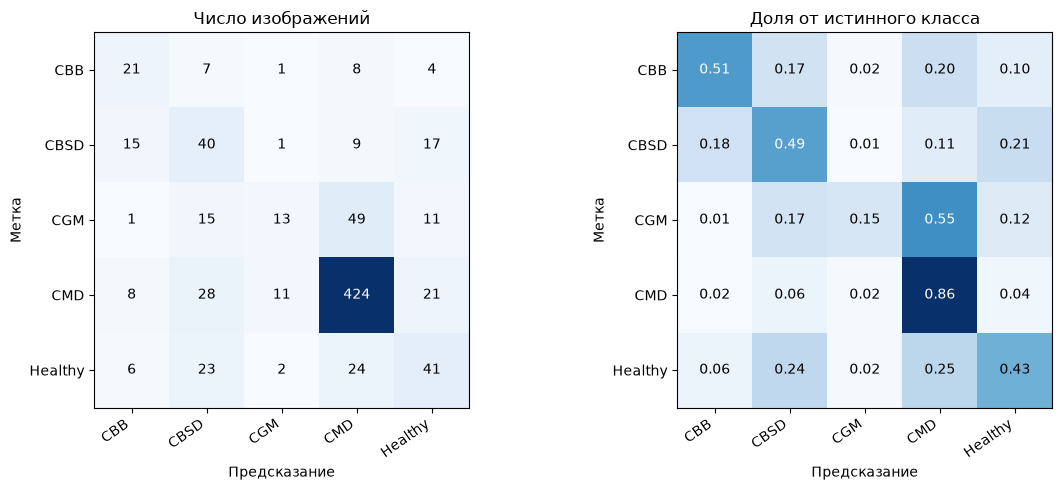

Лучший F1 у CMD - 0.8429, худший у CGM - 0.2222. Найдено 13 из 89 CGM; 49 отнесены к CMD. Среди Healthy ошибочно названы больными 55 из 96.

In [3]:
p, r, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=range(5), zero_division=0)
per_class = pd.DataFrame(dict(n=support, precision=p, recall=r, f1=f1), index=CLASSES)
per_class.index.name = "class"
per_class.to_csv(REPORTS / "per_class.csv")
display(per_class.round(4))
cm = confusion_matrix(y_true, y_pred, labels=range(5))
pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(REPORTS / "confusion_matrix.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, matrix, title, fmt in zip(axes, [cm, cm / cm.sum(1, keepdims=True)],
        ["Число изображений", "Доля от истинного класса"], ["d", ".2f"]):
    im = ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(range(5), CLASSES, rotation=35, ha="right")
    ax.set_yticks(range(5), CLASSES)
    ax.set_xlabel("Предсказание"); ax.set_ylabel("Метка")
    ax.set_title(title)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, format(matrix[i, j], fmt), ha="center", va="center",
                    color="white" if matrix[i, j] > matrix.max() * .5 else "black")
fig.tight_layout(); fig.savefig(FIGURES / "confusion_matrix.png", dpi=150); plt.show(); plt.close(fig)
display(Markdown(f"Лучший F1 у CMD - {per_class.loc['CMD', 'f1']:.4f}, худший у CGM - {per_class.loc['CGM', 'f1']:.4f}. "
    f"Найдено {cm[2,2]} из {cm[2].sum()} CGM; {cm[2,3]} отнесены к CMD. "
    f"Среди Healthy ошибочно названы больными {cm[4].sum()-cm[4,4]} из {cm[4].sum()}."))

Покажем пять ошибок: по одной на каждый истинный класс.
Берем самое частое ошибочное направление внутри класса и пример с медианной уверенностью модели.
Это примеры ошибок на val; причины ниже это гипотезы по фото

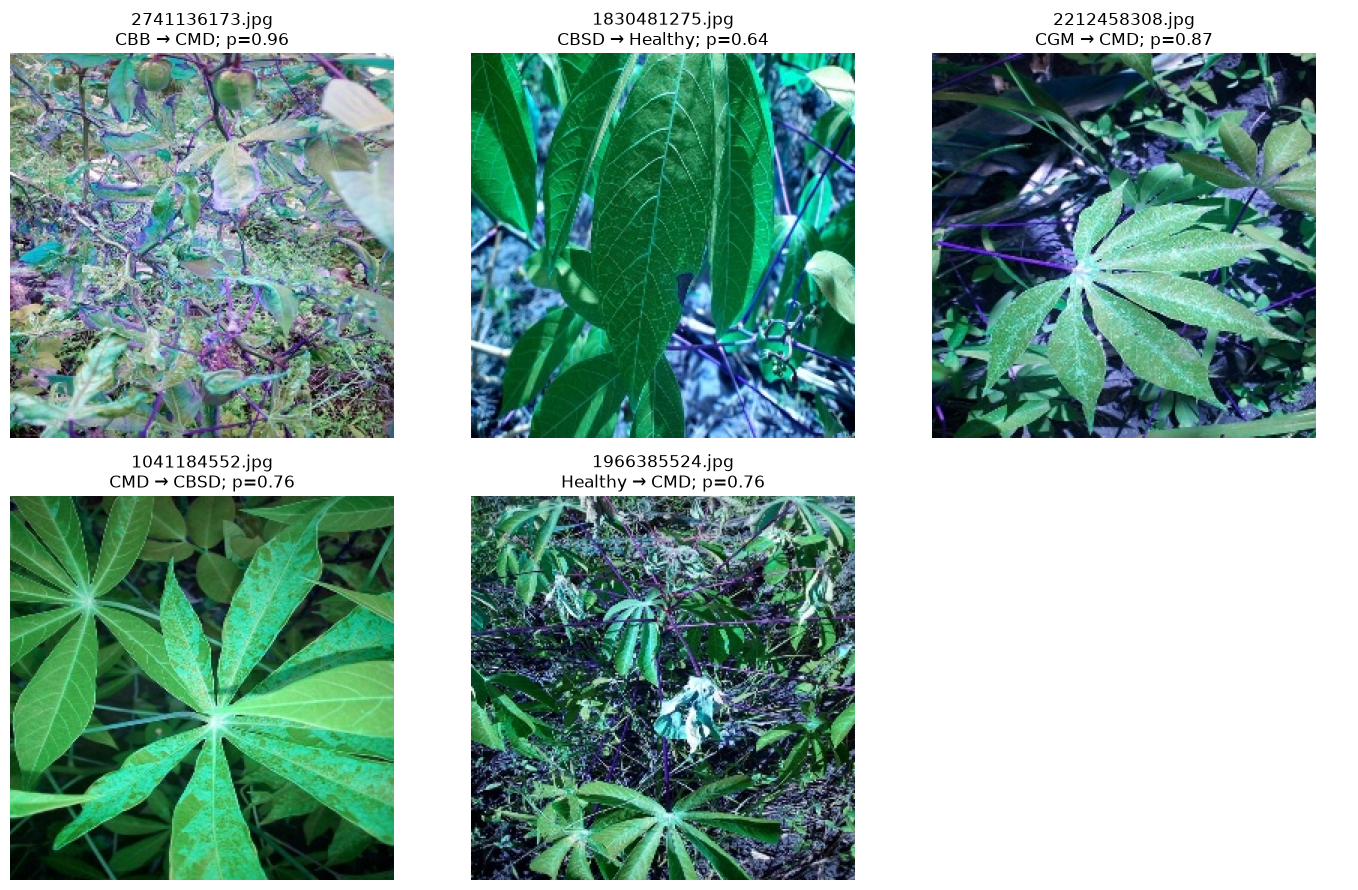

2741136173.jpg, CBB → CMD: Листья сняты издалека, много фона. Гипотеза: после resize 128 теряются мелкие признаки болезни.

1830481275.jpg, CBSD → Healthy: Лист выглядит преимущественно зеленым, видны мелкие светлые участки. Гипотеза: признаки болезни недостаточно выражены для модели.

2212458308.jpg, CGM → CMD: На листе светлые пятна и неоднородная окраска. Гипотеза: похожие внешние признаки CGM и CMD мешают их разделить.

1041184552.jpg, CMD → CBSD: В кадре несколько перекрывающихся листьев. Гипотеза: модель смешивает признаки разных листьев и не выделяет нужный.

1966385524.jpg, Healthy → CMD: Много листьев, веток и темных участков. Гипотеза: фон и освещение создают признаки, похожие на болезнь.

In [9]:
explanations = {
    "2741136173.jpg": "Листья сняты издалека, много фона. Гипотеза: после resize 128 теряются мелкие признаки болезни.",
    "1830481275.jpg": "Лист выглядит преимущественно зеленым, видны мелкие светлые участки. Гипотеза: признаки болезни недостаточно выражены для модели.",
    "2212458308.jpg": "На листе светлые пятна и неоднородная окраска. Гипотеза: похожие внешние признаки CGM и CMD мешают их разделить.",
    "1041184552.jpg": "В кадре несколько перекрывающихся листьев. Гипотеза: модель смешивает признаки разных листьев и не выделяет нужный.",
    "1966385524.jpg": "Много листьев, веток и темных участков. Гипотеза: фон и освещение создают признаки, похожие на болезнь.",
}
error_rows = []
for k, name in enumerate(CLASSES):
    errors = clean[(clean.label == k) & (clean.prediction != k)].copy()
    common_prediction = errors.prediction.value_counts().idxmax()
    errors = errors[errors.prediction == common_prediction]
    errors["confidence"] = errors[f"prob_{CLASSES[int(common_prediction)]}"]
    errors = errors.sort_values(["confidence", "image_id"])
    row = errors.iloc[len(errors) // 2]
    assert row.image_id in explanations, "Пример изменился: нужно заново посмотреть фото и объяснение"
    error_rows.append(dict(image_id=row.image_id, true_class=name, predicted_class=CLASSES[int(row.prediction)],
        confidence=float(row.confidence), pair_n=len(errors), explanation=explanations[row.image_id]))
examples = pd.DataFrame(error_rows)
examples.to_csv(REPORTS / "error_examples.csv", index=False)
clean[clean.label != clean.prediction].to_csv(REPORTS / "all_errors.csv", index=False)
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, row in zip(axes.ravel(), examples.itertuples()):
    with Image.open(IMAGE_DIR / row.image_id) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{row.image_id}\n{row.true_class} → {row.predicted_class}; p={row.confidence:.2f}")
    ax.axis("off")
for ax in axes.ravel()[len(examples):]: ax.axis("off")
fig.tight_layout(); fig.savefig(FIGURES / "error_examples.png", dpi=150); plt.show(); plt.close(fig)
for row in examples.itertuples():
    display(Markdown(f"{row.image_id}, {row.true_class} → {row.predicted_class}: {row.explanation}"))

### 3. Диагностика по срезам

Кроме классов проверяем два среза - яркость и контраст. Они связаны с гипотезой про освещение из ДЗ2.

Яркость - среднее значение grayscale после resize; контраст - его стандартное отклонение.
Границы трех групп берем по 1/3 и 2/3 квантилям **train**, затем применяем к val.
Во всех группах macro F1 считаем по тем же пяти классам, отдельно показываем размер и accuracy.
Разный состав классов может влиять на сравнение групп; причинную связь по срезам не устанавливаем.

,slice,group,n,f1_macro,accuracy,errors
0,brightness,низкая,266,0.4241,0.6241,100
1,brightness,средняя,276,0.4706,0.6957,84
2,brightness,высокая,258,0.4220,0.7016,77
3,contrast,низкий,260,0.4789,0.6923,80
4,contrast,средний,257,0.5063,0.6770,83
5,contrast,высокий,283,0.4311,0.6537,98


,slice,group,CBB,CBSD,CGM,CMD,Healthy
0,brightness,низкая,25,31,25,150,35
1,brightness,средняя,9,29,34,173,31
2,brightness,высокая,7,22,30,169,30
3,contrast,низкий,12,23,31,170,24
4,contrast,средний,16,30,33,145,33
5,contrast,высокий,13,29,25,177,39


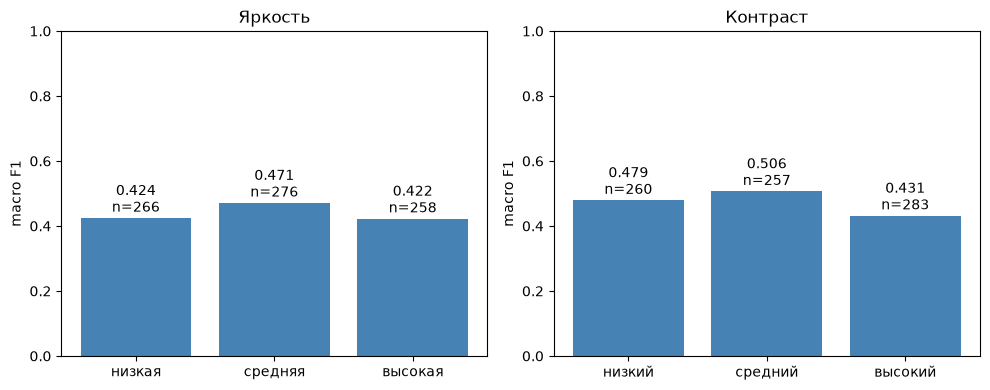

По яркости: минимальный macro F1 у группы «высокая» - 0.4220 (n=258), максимальный у «средняя» - 0.4706 (n=276).

По контраста: минимальный macro F1 у группы «высокий» - 0.4311 (n=283), максимальный у «средний» - 0.5063 (n=257).

In [10]:
resize = T.Resize((CFG["size"], CFG["size"]))
def image_stats(frame):
    rows = []
    for row in frame.itertuples():
        with Image.open(IMAGE_DIR / row.image_id) as image:
            gray = np.asarray(resize(image.convert("RGB")).convert("L"), dtype=np.float32) / 255.0
        rows.append(dict(image_id=row.image_id, brightness=float(gray.mean()), contrast=float(gray.std())))
    return pd.DataFrame(rows)

train_stats = image_stats(train)
val_stats = image_stats(val)
train_stats.to_csv(REPORTS / "train_image_stats.csv", index=False)
val_stats.to_csv(REPORTS / "val_image_stats.csv", index=False)
slice_rows, compositions, thresholds = [], [], {}
for feature, labels in [("brightness", ["низкая", "средняя", "высокая"]),
                        ("contrast", ["низкий", "средний", "высокий"])]:
    cuts = train_stats[feature].quantile([1/3, 2/3]).to_numpy()
    thresholds[feature] = cuts.tolist()
    val_stats[f"{feature}_group"] = pd.cut(val_stats[feature], [-np.inf, *cuts, np.inf], labels=labels)
    for label in labels:
        mask = (val_stats[f"{feature}_group"] == label).to_numpy()
        count = int(mask.sum())
        pred_group, true_group = y_pred[mask], y_true[mask]
        f1_group = precision_recall_fscore_support(true_group, pred_group, labels=range(5), average="macro", zero_division=0)[2]
        slice_rows.append(dict(slice=feature, group=label, n=count, f1_macro=f1_group,
            accuracy=float((true_group == pred_group).mean()), errors=int((true_group != pred_group).sum())))
        compositions.append(dict(slice=feature, group=label, **{c: int((true_group == k).sum()) for k, c in enumerate(CLASSES)}))
slices = pd.DataFrame(slice_rows)
slices.to_csv(REPORTS / "slices.csv", index=False)
pd.DataFrame(compositions).to_csv(REPORTS / "slice_class_counts.csv", index=False)
(REPORTS / "slice_thresholds.json").write_text(json.dumps(thresholds, ensure_ascii=False, indent=2))
display(slices.round(4))
display(pd.DataFrame(compositions))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, feature, title in zip(axes, ["brightness", "contrast"], ["Яркость", "Контраст"]):
    table = slices[slices.slice == feature]
    bars = ax.bar(table.group, table.f1_macro, color="steelblue")
    ax.set_title(title); ax.set_ylabel("macro F1"); ax.set_ylim(0, 1)
    for bar, row in zip(bars, table.itertuples()):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+.02, f"{row.f1_macro:.3f}\nn={row.n}", ha="center")
fig.tight_layout(); fig.savefig(FIGURES / "slices.png", dpi=150); plt.show(); plt.close(fig)
for feature, name in [("brightness", "яркости"), ("contrast", "контраста")]:
    table = slices[slices.slice == feature]
    low = table.loc[table.f1_macro.idxmin()]
    high = table.loc[table.f1_macro.idxmax()]
    display(Markdown(f"По {name}: минимальный macro F1 у группы «{low['group']}» - {low.f1_macro:.4f} (n={low.n}), "
        f"максимальный у «{high['group']}» - {high.f1_macro:.4f} (n={high.n})."))

Лучший результат у средней яркости и среднего контраста. Самые яркие фото не оказались самыми простыми: macro F1 = 0.4220.
В этой группе всего 7 CBB; несколько ошибок заметно меняют F1 класса.

При высоком контрасте macro F1 ниже, чем при среднем: 0.4311 против 0.5063.
Гипотеза: резкие тени и неоднородный фон мешают различать симптомы.
Но контраст всего кадра зависит и от фона

### 4. Проверка устойчивости

Две проверки, без переобучения:

1. Яркость: умножаем RGB на 0.7 или 1.3.
2. Гауссовский шум: sigma=0.03 или 0.06 при значениях пикселей от 0 до 1.

Искажения применяются после resize и до ImageNet normalization; значения обрезаются до [0, 1].
За раз меняется один фактор. Модель, val и метки остаются прежними.
Для каждого фото шум фиксирован по seed и image_id; при другой sigma меняется только его сила.

In [11]:
conditions = [("clean", "исходные фото", 1.0, 0.0)]
conditions += [(f"brightness_{factor:g}", f"яркость ×{factor:g}", factor, 0.0) for factor in CFG["brightness_factors"]]
conditions += [(f"noise_{sigma:g}", f"шум sigma={sigma:g}", 1.0, sigma) for sigma in CFG["noise_sigmas"]]
probabilities = {"clean": prob_clean}
robustness_rows = []
for name, description, brightness, sigma in conditions:
    prob = prob_clean if name == "clean" else predict(val, brightness=brightness, noise_sigma=sigma)
    probabilities[name] = prob
    save_predictions(name, prob)
    row = dict(condition=name, description=description, brightness=brightness, noise_sigma=sigma,
               **calculate_metrics(y_true, prob))
    row["delta_f1"] = row["f1_macro"] - metrics_clean["f1_macro"]
    row["prediction_change_rate"] = float((prob.argmax(1) != y_pred).mean())
    robustness_rows.append(row)
    print(f"{description}: macro F1={row['f1_macro']:.4f}, Δ={row['delta_f1']:+.4f}")
robustness = pd.DataFrame(robustness_rows)
robustness.to_csv(REPORTS / "robustness.csv", index=False)
display(robustness[["description", "n", "f1_macro", "delta_f1", "accuracy", "f1_healthy", "prediction_change_rate"]].round(4))

исходные фото: macro F1=0.4727, Δ=+0.0000
яркость ×0.7: macro F1=0.4112, Δ=-0.0615
яркость ×1.3: macro F1=0.4362, Δ=-0.0365
шум sigma=0.03: macro F1=0.4300, Δ=-0.0427
шум sigma=0.06: macro F1=0.4373, Δ=-0.0354


,description,n,f1_macro,delta_f1,accuracy,f1_healthy,prediction_change_rate
0,исходные фото,800,0.4727,0.0000,0.6738,0.4316,0.0000
1,яркость ×0.7,800,0.4112,-0.0615,0.6288,0.3814,0.1262
2,яркость ×1.3,800,0.4362,-0.0365,0.6450,0.4000,0.1262
3,шум sigma=0.03,800,0.4300,-0.0427,0.6650,0.2571,0.1212
4,шум sigma=0.06,800,0.4373,-0.0354,0.6462,0.2797,0.2112


Дополнительно оценим разброс разницы с исходными фото: 500 парных bootstrap-повторов,
внутри каждого истинного класса сохраняем его размер. В пару попадают те же изображения
до и после искажения. Это интервал для текущего val и выбранной модели,
он не учитывает другой seed обучения, другое поле съемки или выбор модели по этому же val.

,description,f1_macro,delta_f1,delta_ci_low,delta_ci_high
0,исходные фото,0.4727,0.0000,0.0000,0.0000
1,яркость ×0.7,0.4112,-0.0615,-0.0917,-0.0343
2,яркость ×1.3,0.4362,-0.0365,-0.0693,-0.0062
3,шум sigma=0.03,0.4300,-0.0427,-0.0800,-0.0088
4,шум sigma=0.06,0.4373,-0.0354,-0.0803,0.0091


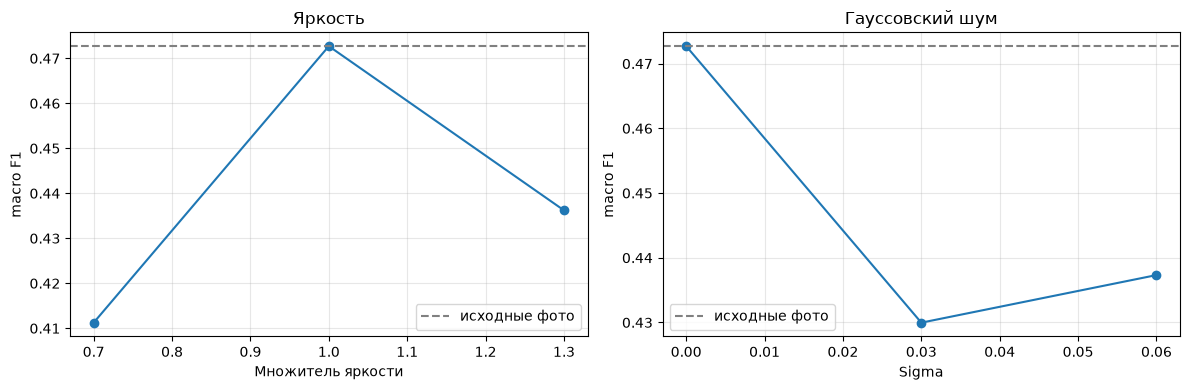

яркость ×0.7: macro F1 0.4112, Δ -0.0615; 95% bootstrap интервал Δ [-0.0917; -0.0343], интервал не включает 0.

яркость ×1.3: macro F1 0.4362, Δ -0.0365; 95% bootstrap интервал Δ [-0.0693; -0.0062], интервал не включает 0.

шум sigma=0.03: macro F1 0.4300, Δ -0.0427; 95% bootstrap интервал Δ [-0.0800; -0.0088], интервал не включает 0.

шум sigma=0.06: macro F1 0.4373, Δ -0.0354; 95% bootstrap интервал Δ [-0.0803; +0.0091], интервал включает 0.

In [12]:
def macro_f1_from_labels(true, pred):
    matrix = np.bincount(true * 5 + pred, minlength=25).reshape(5, 5)
    denominator = matrix.sum(0) + matrix.sum(1)
    values = np.divide(2 * np.diag(matrix), denominator, out=np.zeros(5, dtype=float), where=denominator > 0)
    return float(values.mean())

assert np.isclose(macro_f1_from_labels(y_true, y_pred), metrics_clean["f1_macro"])
rng = np.random.default_rng(SEED)
class_indices = [np.flatnonzero(y_true == k) for k in range(5)]
bootstrap_indices = [np.concatenate([rng.choice(idx, size=len(idx), replace=True) for idx in class_indices])
                     for _ in range(CFG["bootstrap_repeats"])]
intervals = []
for name, _, _, _ in conditions:
    if name == "clean":
        intervals.append(dict(condition=name, delta_ci_low=0.0, delta_ci_high=0.0))
        continue
    corrupted_pred = probabilities[name].argmax(1)
    deltas = [macro_f1_from_labels(y_true[idx], corrupted_pred[idx]) - macro_f1_from_labels(y_true[idx], y_pred[idx])
              for idx in bootstrap_indices]
    lo, hi = np.quantile(deltas, [.025, .975])
    intervals.append(dict(condition=name, delta_ci_low=float(lo), delta_ci_high=float(hi)))
robustness = robustness.merge(pd.DataFrame(intervals), on="condition", validate="one_to_one")
robustness.to_csv(REPORTS / "robustness.csv", index=False)
display(robustness[["description", "f1_macro", "delta_f1", "delta_ci_low", "delta_ci_high"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, names, x, title in [
    (axes[0], ["brightness_0.7", "clean", "brightness_1.3"], [.7, 1.0, 1.3], "Яркость"),
    (axes[1], ["clean", "noise_0.03", "noise_0.06"], [.0, .03, .06], "Гауссовский шум")]:
    table = robustness.set_index("condition").loc[names]
    ax.plot(x, table.f1_macro, marker="o")
    ax.axhline(metrics_clean["f1_macro"], linestyle="--", color="gray", label="исходные фото")
    ax.set_title(title); ax.set_xlabel("Множитель яркости" if title == "Яркость" else "Sigma")
    ax.set_ylabel("macro F1"); ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "robustness.png", dpi=150); plt.show(); plt.close(fig)
for row in robustness.itertuples():
    if row.condition == "clean": continue
    interval = "интервал включает 0" if row.delta_ci_low <= 0 <= row.delta_ci_high else "интервал не включает 0"
    display(Markdown(f"{row.description}: macro F1 {row.f1_macro:.4f}, Δ {row.delta_f1:+.4f}; "
        f"95% bootstrap интервал Δ [{row.delta_ci_low:+.4f}; {row.delta_ci_high:+.4f}], {interval}."))

При затемнении macro F1 снизился на 0.0615, при увеличении яркости - на 0.0365.
Для обоих изменений bootstrap интервал разницы не включает 0. Модель чувствительна к яркости даже после train-аугментаций.

Шум sigma=0.03 снизил F1 Healthy с 0.4316 до 0.2571.
При sigma=0.06 общий macro F1 немного выше, чем при 0.03, но ниже исходного; зависимость не монотонна.
Интервал разницы с исходными фото для sigma=0.06 включает 0. Это не означает устойчивость: предсказания изменились у 21.1% изображений.

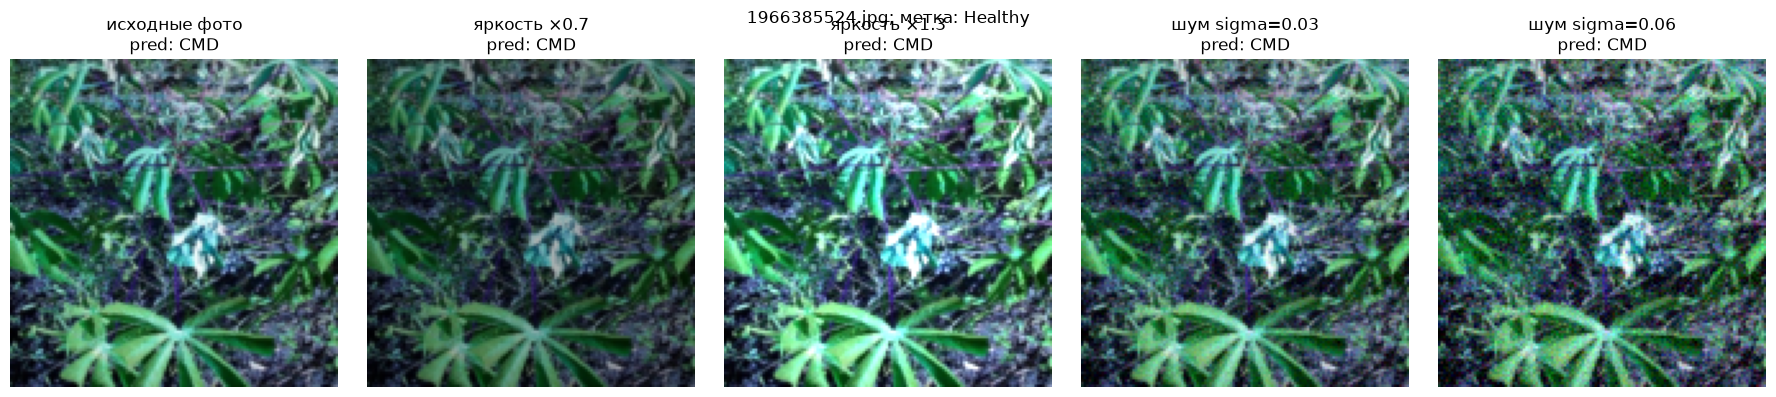

In [13]:
# Один пример при всех условиях: видно, насколько сильны искажения.
example_id = examples.iloc[-1].image_id
example_frame = val[val.image_id == example_id].reset_index(drop=True)
mean = torch.tensor(CFG["mean"])[:, None, None]
std = torch.tensor(CFG["std"])[:, None, None]
fig, axes = plt.subplots(1, len(conditions), figsize=(18, 4))
image_i = int(val.index[val.image_id == example_id][0])
for ax, (name, description, brightness, sigma) in zip(axes, conditions):
    x, _ = CassavaValidation(example_frame, brightness=brightness, noise_sigma=sigma)[0]
    ax.imshow((x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title(f"{description}\npred: {CLASSES[probabilities[name][image_i].argmax()]}")
    ax.axis("off")
fig.suptitle(f"{example_id}; метка: Healthy")
fig.tight_layout(); fig.savefig(FIGURES / "perturbation_examples.png", dpi=150); plt.show(); plt.close(fig)

### 5. Ограничения модели

Границы применимости:
Модель выбирает один из пяти классов Cassava. Другие растения, неизвестные болезни и несколько заболеваний сразу она не распознает как отдельные случаи.
Проверялись только фотографии из того же датасета. Работа на новых фермах, камерах и телефонах не проверена.

Источники ошибок:
В train всего 3200 изображений, классы несбалансированы. Resize 128 может скрывать мелкие симптомы.
Есть похожие внешние признаки заболеваний, фон и неоднозначные метки. Неверную разметку по одному предсказанию модели утверждать нельзя.

Риски применения:
Ошибка Healthy → болезнь дает ложную тревогу; болезнь → Healthy может оставить больное растение без внимания.
Низкий recall CGM ограничивает пользу для этого заболевания. Модель можно рассматривать как предварительную подсказку, но не как самостоятельный диагноз.
Высокая вероятность softmax не гарантирует правильный ответ; калибровка уверенности не проверялась.

Утечки:
По image_id train и val не пересекаются. Границы срезов рассчитаны только по train, нормализация взята из ImageNet.
Групп растений и ферм нет; похожие фото могли попасть в обе части. Для контроля нужны поиск дубликатов и split по растению/ферме при наличии метаданных.
Лучшая модель и эпоха выбраны по этому же val: независимой итоговой оценки нет. После этого анализа val уже используется для принятия решений; будущие улучшения нужно проверять на отдельной отложенной выборке.

### 6. Выводы

In [9]:
worst_class = per_class.f1.idxmin()
worst_condition = robustness.loc[robustness.f1_macro.idxmin()]
summary = (
    f"Что получилось: macro F1 {metrics_clean['f1_macro']:.4f} на 800 val изображениях; предсказания ДЗ2 воспроизвелись.\n\n"
    f"Где слаб: {worst_class}, F1 {per_class.loc[worst_class, 'f1']:.4f}. Ошибки есть у всех классов, в том числе у Healthy.\n\n"
    f"Устойчивость: минимальный macro F1 в проверках - {worst_condition.f1_macro:.4f}, условие «{worst_condition.description}». "
    "Чувствительность к изменению фото ограничивает доверие к модели в других условиях съемки.\n\n"
    "По срезам видны различия, но они не доказывают влияние одного освещения: меняются фон и состав классов.\n\n"
    "Перед практическим применением нужны отдельные данные из новых условий, проверка дубликатов и разбор ошибок с экспертом."
)
display(Markdown(summary))
(REPORTS / "conclusions.txt").write_text(summary + "\n")
# Все числа для отчетов сохранены; после исполнения notebook содержит и таблицы, и рисунки.
artifacts = dict(model=CFG["model_name"], clean_f1_macro=metrics_clean["f1_macro"],
    errors_examples=len(examples), slice_definitions=2, robustness_checks=2,
    n_validation=len(val), checkpoint_sha256=environment["checkpoint_sha256"],
    all_clean_predictions_match_hw2=True)
(REPORTS / "run_summary.json").write_text(json.dumps(artifacts, ensure_ascii=False, indent=2))

Что получилось: macro F1 0.4727 на 800 val изображениях; предсказания ДЗ2 воспроизвелись.

Где слаб: CGM, F1 0.2222. Ошибки есть у всех классов, в том числе у Healthy.

Устойчивость: минимальный macro F1 в проверках - 0.4112, условие «яркость ×0.7». Чувствительность к изменению фото ограничивает доверие к модели в других условиях съемки.

По срезам видны различия, но они не доказывают влияние одного освещения: меняются фон и состав классов.

Перед практическим применением нужны отдельные данные из новых условий, проверка дубликатов и разбор ошибок с экспертом.

300

### 7. Запуск и файлы

Запускать ячейки по порядку. Настройки - configs/analysis.json.
Нужны `../hw_2/checkpoints/full_h1_h2.pt` и `../hw_1/data/cassava_train` (см. configs/analysis.json).
Обучение и скачивание весов не требуются.
